In [2]:
from pathlib import Path
import tarfile
import urllib.request
import pandas as pd

In [3]:
def load_house_data():
    data_directory = Path("datasets/housing.tgz")
    if not data_directory.is_file():
        Path("datasets").mkdir(parents=True, exist_ok=True)
        url = "https://github.com/ageron/data/raw/main/housing.tgz"
        urllib.request.urlretrieve(url, data_directory)
    with tarfile.open(data_directory) as file:
        file.extractall(path="datasets")
    return pd.read_csv(Path("datasets/housing/housing.csv"))

In [4]:
housing = load_house_data()

In [5]:
housing.head()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY


In [6]:
housing.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20640 non-null  float64
 1   latitude            20640 non-null  float64
 2   housing_median_age  20640 non-null  float64
 3   total_rooms         20640 non-null  float64
 4   total_bedrooms      20433 non-null  float64
 5   population          20640 non-null  float64
 6   households          20640 non-null  float64
 7   median_income       20640 non-null  float64
 8   median_house_value  20640 non-null  float64
 9   ocean_proximity     20640 non-null  object 
dtypes: float64(9), object(1)
memory usage: 1.6+ MB


In [7]:
# 4   total_bedrooms      20433 non-null  float64

In [8]:
# 9   ocean_proximity     20640 non-null  object
housing["ocean_proximity"].value_counts()

ocean_proximity
<1H OCEAN     9136
INLAND        6551
NEAR OCEAN    2658
NEAR BAY      2290
ISLAND           5
Name: count, dtype: int64

In [9]:
housing.describe()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value
count,20640.000000,20640.000000,20640.000000,20640.000000,20433.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,-119.569704,35.631861,28.639486,2635.763081,537.870553,1425.476744,499.539680,3.870671,206855.816909
std,2.003532,2.135952,12.585558,2181.615252,421.385070,1132.462122,382.329753,1.899822,115395.615874
min,-124.350000,32.540000,1.000000,2.000000,1.000000,3.000000,1.000000,0.499900,14999.000000
25%,-121.800000,33.930000,18.000000,1447.750000,296.000000,787.000000,280.000000,2.563400,119600.000000
50%,-118.490000,34.260000,29.000000,2127.000000,435.000000,1166.000000,409.000000,3.534800,179700.000000
75%,-118.010000,37.710000,37.000000,3148.000000,647.000000,1725.000000,605.000000,4.743250,264725.000000
max,-114.310000,41.950000,52.000000,39320.000000,6445.000000,35682.000000,6082.000000,15.000100,500001.000000


In [10]:
housing.isnull().sum()

longitude               0
latitude                0
housing_median_age      0
total_rooms             0
total_bedrooms        207
population              0
households              0
median_income           0
median_house_value      0
ocean_proximity         0
dtype: int64

In [11]:
import matplotlib.pyplot as plt

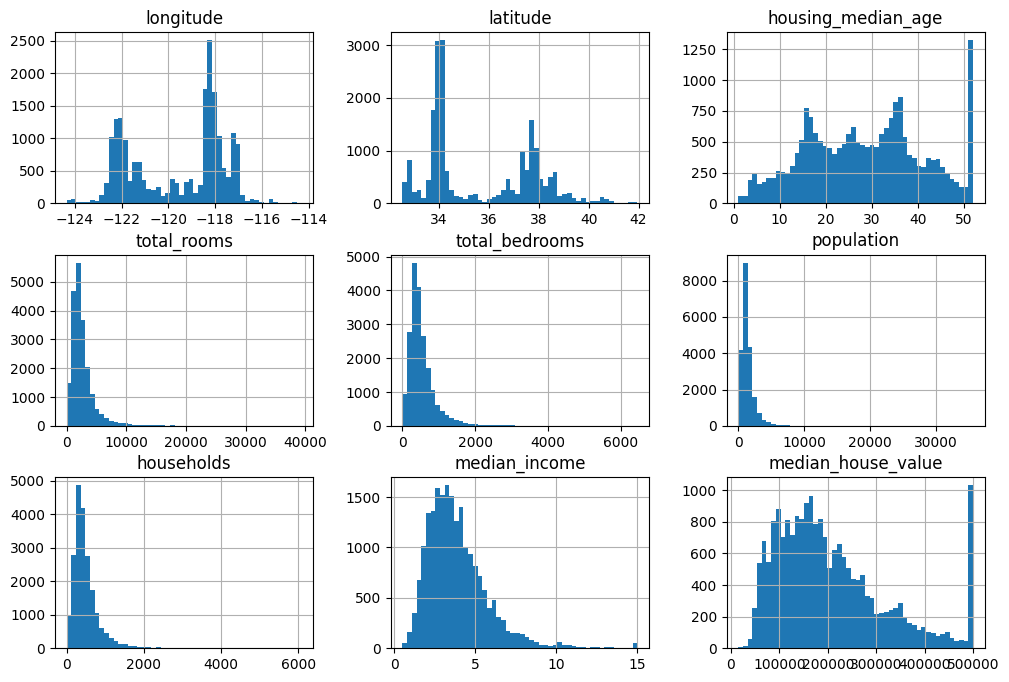

In [12]:
housing.hist(bins=50,figsize=(12,8))
plt.show()

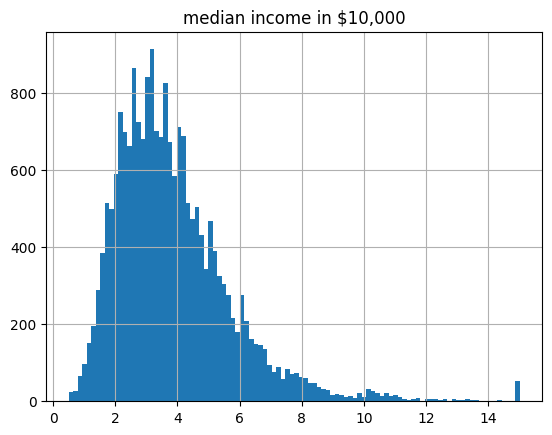

In [13]:
housing["median_income"].hist(bins=100)
plt.title("median income in $10,000")
plt.show()

In [14]:
import numpy as np
np.random.seed(42)

In [15]:
def suffle_and_split_data(data,test_ratio):
    suffle_inedxes = np.random.permutation(len(data))
    test_size = int(test_ratio*len(data))
    test_indexes = suffle_inedxes[:test_size]
    train_indexes = suffle_inedxes[test_size:]
    return data.iloc[train_indexes], data.iloc[test_indexes]

In [16]:
train_set,test_set = suffle_and_split_data(housing,0.2)

In [17]:
len(housing),len(train_set),len(test_set),len(train_set)+len(test_set)

(20640, 16512, 4128, 20640)

In [18]:
# above function will break the next time you fetch an updated dataset.
# we use sklearn library.

In [19]:
from sklearn.model_selection import train_test_split
train_set, test_set = train_test_split(housing, test_size=0.2,random_state=42)

In [20]:
len(train_set),len(test_set)

(16512, 4128)

### stratified sampling:

In [21]:
housing["median_income"].min(),housing["median_income"].max()

(np.float64(0.4999), np.float64(15.0001))

In [22]:
#pd.cut() function to create an income category
#attribute with five categories (labeled from 1 to 5); category 1 ranges from 0
#to 1.5 (i.e., less than $15,000), category 2 from 1.5 to 3, and so on:

In [23]:
housing["income_cat"] = pd.cut(housing["median_income"],bins=[0.,1.5,3.0,4.5,6.,np.inf],labels=[1,2,3,4,5]) # np.inf = infinity

In [24]:
# aslo we can create a function
def create_income_bins(df):
    df = df.copy()
    df["income_cat"] = pd.cut(df["median_income"],
                             bins=[0.,1.5,3.0,4.5,6.,np.inf],
                             labels=[1,2,3,4,5])
    return df
#housing = create_income_bins(housing)

In [25]:
housing.income_cat.value_counts().sort_index()

income_cat
1     822
2    6581
3    7236
4    3639
5    2362
Name: count, dtype: int64

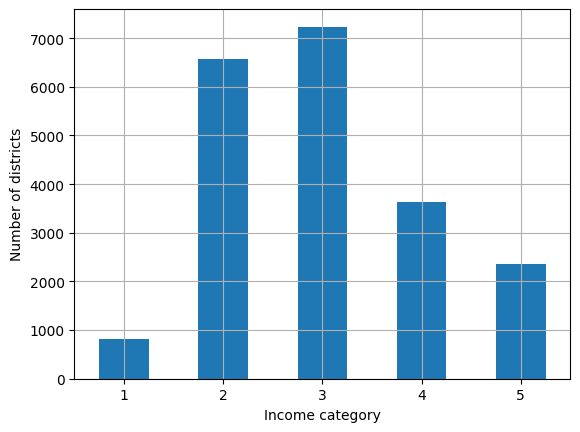

In [26]:
housing.income_cat.value_counts().sort_index().plot(rot=0,grid=True,kind="bar")
plt.xlabel("Income category")
plt.ylabel("Number of districts")
plt.show()

In [27]:
# now we do stratified sampling based on the income category.

In [28]:
# we splts data into 10 different times, we take first one. This is useful in cross validation.
# split() method returns indices (row numbers)
# strat_splits.append(...): It takes the training/test pair and saves it into a list. Since n_splits=10, this list will eventually hold 10 different pairs of dataframes.

In [29]:
from sklearn.model_selection import StratifiedShuffleSplit

In [30]:
splitter  = StratifiedShuffleSplit(n_splits=10,test_size=0.2,random_state=42)
strat_splits = [] # contains all 10 splits
for test_index, train_index in splitter.split(housing,housing["income_cat"]):
    strat_train_set_n = housing.iloc[test_index]
    strat_test_set_n = housing.iloc[train_index]
    strat_splits.append([strat_train_set_n,strat_test_set_n])


In [31]:
strat_train_set, strat_test_set = strat_splits[0]

In [32]:
# strat_splits[0]

In [33]:
# if we want only one split, we have simple method 
strat_train_set, strat_test_set = train_test_split(housing,test_size=0.2,random_state=42,stratify=housing["income_cat"])

In [34]:
# strat_train_set["income_cat"].value_counts()/len(strat_train_set)
strat_train_set["income_cat"].value_counts(normalize=True)

income_cat
3    0.350594
2    0.318859
4    0.176296
5    0.114462
1    0.039789
Name: proportion, dtype: float64

In [35]:
strat_test_set["income_cat"].value_counts()/len(strat_test_set)

income_cat
3    0.350533
2    0.318798
4    0.176357
5    0.114341
1    0.039971
Name: count, dtype: float64

In [36]:
# there is no need of income_cat column. so, drop. reverting the data back to original state.
for set_ in (strat_train_set,strat_test_set):
    set_.drop("income_cat",axis=1,inplace=True)

In [37]:
strat_train_set.head()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
13096,-122.42,37.80,52.0,3321.0,1115.0,1576.0,1034.0,2.0987,458300.0,NEAR BAY
14973,-118.38,34.14,40.0,1965.0,354.0,666.0,357.0,6.0876,483800.0,<1H OCEAN
3785,-121.98,38.36,33.0,1083.0,217.0,562.0,203.0,2.4330,101700.0,INLAND
14689,-117.11,33.75,17.0,4174.0,851.0,1845.0,780.0,2.2618,96100.0,INLAND
20507,-118.15,33.77,36.0,4366.0,1211.0,1912.0,1172.0,3.5292,361800.0,NEAR OCEAN


In [38]:
# make sure we have put the test set aside and we are only exploring the training set

## Discover and Visualize the Data to Gain Insights

In [39]:
# make a copy and revert whaen need of original data
housing = strat_train_set.copy()

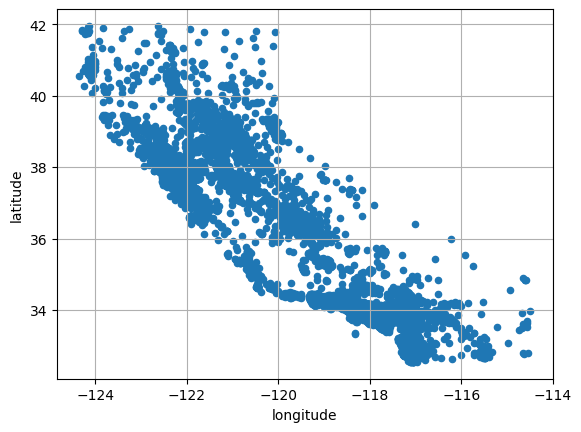

In [40]:
housing.plot(x="longitude",y = "latitude",kind="scatter",grid=True)
plt.show()

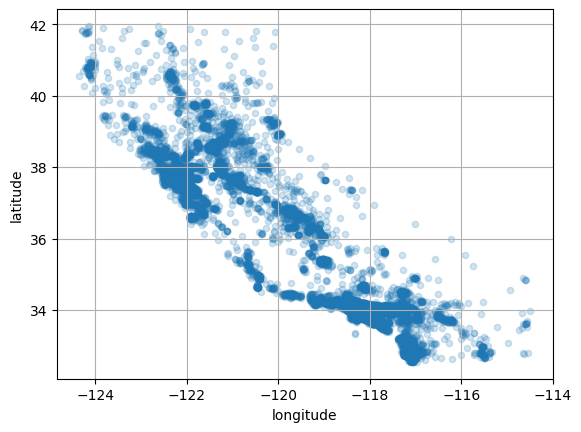

In [41]:
housing.plot(x="longitude",y = "latitude",kind="scatter",grid=True,alpha=0.2)
plt.show()

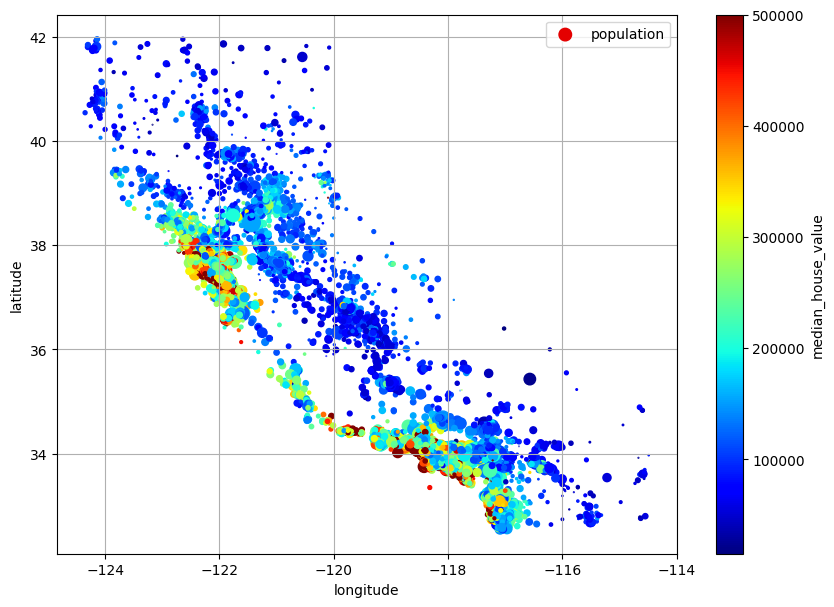

In [42]:
housing.plot(kind="scatter",x="longitude",y = "latitude",grid=True,s=housing["population"]/100,c="median_house_value",
            cmap="jet",colorbar=True,label="population",legend=True,sharex=False, figsize=(10, 7))
plt.show()

### correlations

In [43]:
# compute the standard correlation coefficient (also called Pearson’s r)
corr_matrix = housing.corr(numeric_only=True)

In [44]:
corr_matrix

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value
longitude,1.000000,-0.924213,-0.102937,0.044558,0.068210,0.104236,0.054261,-0.016542,-0.050859
latitude,-0.924213,1.000000,0.005692,-0.036753,-0.066391,-0.115677,-0.071604,-0.078137,-0.139584
housing_median_age,-0.102937,0.005692,1.000000,-0.361710,-0.317978,-0.301906,-0.300075,-0.127043,0.102175
total_rooms,0.044558,-0.036753,-0.361710,1.000000,0.930076,0.863967,0.916143,0.197720,0.137455
total_bedrooms,0.068210,-0.066391,-0.317978,0.930076,1.000000,0.886200,0.978822,-0.006038,0.054635
population,0.104236,-0.115677,-0.301906,0.863967,0.886200,1.000000,0.916237,0.004282,-0.020153
households,0.054261,-0.071604,-0.300075,0.916143,0.978822,0.916237,1.000000,0.013637,0.071426
median_income,-0.016542,-0.078137,-0.127043,0.197720,-0.006038,0.004282,0.013637,1.000000,0.688380
median_house_value,-0.050859,-0.139584,0.102175,0.137455,0.054635,-0.020153,0.071426,0.688380,1.000000


In [45]:
# how each column correlared to median house price
corr_matrix["median_house_value"].sort_values(ascending=False)

median_house_value    1.000000
median_income         0.688380
total_rooms           0.137455
housing_median_age    0.102175
households            0.071426
total_bedrooms        0.054635
population           -0.020153
longitude            -0.050859
latitude             -0.139584
Name: median_house_value, dtype: float64

In [46]:
# observe median_income are highly correlaed. it seems like the most promisingattribute to predict the median house value is the median income

In [47]:
import seaborn as sns

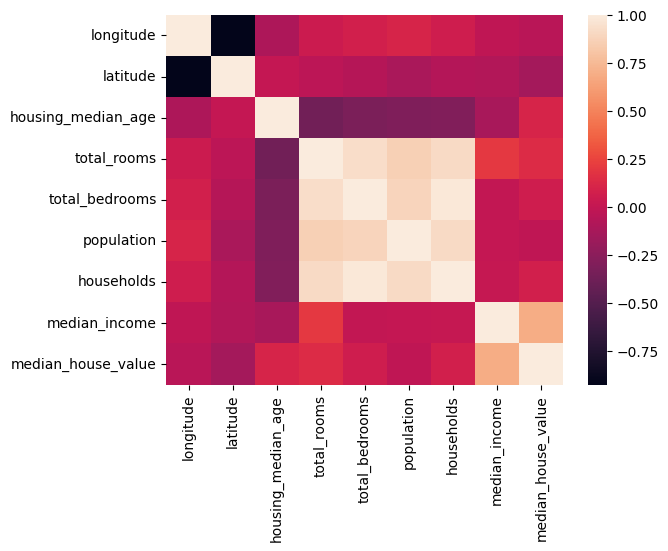

In [48]:
sns.heatmap(corr_matrix)
plt.show()

In [49]:
# attributes = ["median_house_value", "median_income", "total_rooms","housing_median_age"]
# plt.figure(figsize=(12, 8))
# sns.pairplot(housing[attributes],diag_kind="hist")
# plt.show()

In [50]:
# from pandas.plotting import scatter_matrix
# attributes = ["median_house_value", "median_income", "total_rooms","housing_median_age"]
# scatter_matrix(housing[attributes], figsize=(12, 8))
# plt.show()

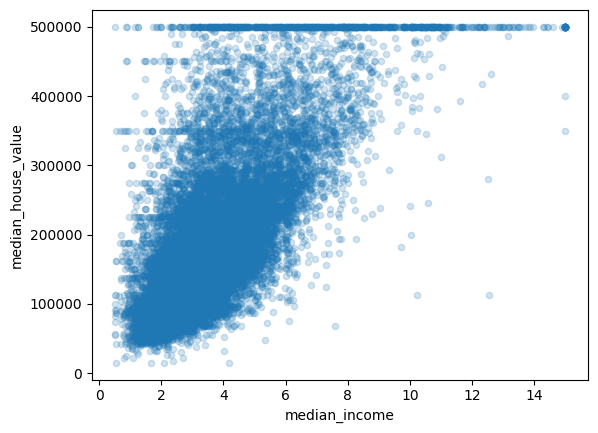

In [51]:
# if we observe correlation between most promising attribute to predict the median house value is the median income
housing.plot(kind="scatter",x="median_income",y="median_house_value",alpha=0.2)
plt.show()

### Experimenting with Attribute Combinations

In [52]:
housing.head(2)

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
13096,-122.42,37.80,52.0,3321.0,1115.0,1576.0,1034.0,2.0987,458300.0,NEAR BAY
14973,-118.38,34.14,40.0,1965.0,354.0,666.0,357.0,6.0876,483800.0,<1H OCEAN


In [53]:
housing["rooms_per_house"] = housing["total_rooms"] / housing["households"]
housing["bedrooms_ratio"] = housing["total_bedrooms"] / housing["total_rooms"]
housing["people_per_house"] = housing["population"] / housing["households"]

In [54]:
corr_matrix = housing.corr(numeric_only=True)

In [55]:
corr_matrix["median_house_value"].sort_values(ascending=False)

median_house_value    1.000000
median_income         0.688380
rooms_per_house       0.143663
total_rooms           0.137455
housing_median_age    0.102175
households            0.071426
total_bedrooms        0.054635
population           -0.020153
people_per_house     -0.038224
longitude            -0.050859
latitude             -0.139584
bedrooms_ratio       -0.256397
Name: median_house_value, dtype: float64

## Prepare the Data for Machine Learning Algorithms

In [56]:
# we don’t necessarily want to apply the same transformations to the predictors and the target values
housing = strat_train_set.drop("median_house_value",axis=1) # creates a copy of strat_train_set without the column, it doesn't actually modify strat_train_set itself, unless you pass inplace=True )
housing_labels = strat_train_set["median_house_value"].copy()

### Data Cleaning

now we want to handle missing values
1. remove the rows contains missing values using dropna()
2. remove the column using drop
3. replace with another value like mean,median,etc. using fillna(). this is called Imputation.

In [57]:
housing.isna().sum()

longitude               0
latitude                0
housing_median_age      0
total_rooms             0
total_bedrooms        168
population              0
households              0
median_income           0
ocean_proximity         0
dtype: int64

In [58]:
# see the null value rows
null_row_index = housing.isnull().any(axis=1)
housing.loc[null_row_index].head()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,ocean_proximity
14452,-120.67,40.50,15.0,5343.0,NaN,2503.0,902.0,3.5962,INLAND
18217,-117.96,34.03,35.0,2093.0,NaN,1755.0,403.0,3.4115,<1H OCEAN
11889,-118.05,34.04,33.0,1348.0,NaN,1098.0,257.0,4.2917,<1H OCEAN
20325,-118.88,34.17,15.0,4260.0,NaN,1701.0,669.0,5.1033,<1H OCEAN
14360,-117.87,33.62,8.0,1266.0,NaN,375.0,183.0,9.8020,<1H OCEAN


In [59]:
housing.dropna(subset=["total_bedrooms"]).isna().sum() # option 1, alsouse inplace=True

longitude             0
latitude              0
housing_median_age    0
total_rooms           0
total_bedrooms        0
population            0
households            0
median_income         0
ocean_proximity       0
dtype: int64

In [60]:
housing_o1 = housing.copy()
housing_o1.dropna(subset=["total_bedrooms"],inplace=True)
housing_o1.loc[null_row_index].head()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,ocean_proximity


In [61]:
# lly do for below options

In [62]:
housing.drop("total_bedrooms",axis=1).isnull().sum()  # option 2

longitude             0
latitude              0
housing_median_age    0
total_rooms           0
population            0
households            0
median_income         0
ocean_proximity       0
dtype: int64

In [63]:
housing_o2 = housing.copy()
housing_o2.drop("total_bedrooms",axis=1)
housing_o2.loc[null_row_index].head()
# observe column is becone NaN value

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,ocean_proximity
14452,-120.67,40.50,15.0,5343.0,NaN,2503.0,902.0,3.5962,INLAND
18217,-117.96,34.03,35.0,2093.0,NaN,1755.0,403.0,3.4115,<1H OCEAN
11889,-118.05,34.04,33.0,1348.0,NaN,1098.0,257.0,4.2917,<1H OCEAN
20325,-118.88,34.17,15.0,4260.0,NaN,1701.0,669.0,5.1033,<1H OCEAN
14360,-117.87,33.62,8.0,1266.0,NaN,375.0,183.0,9.8020,<1H OCEAN


In [64]:
# option 3
median = housing["total_bedrooms"].median()
housing["total_bedrooms"].fillna(median)

13096    1115.0
14973     354.0
3785      217.0
14689     851.0
20507    1211.0
          ...  
14207     597.0
13105     592.0
19301     775.0
19121     873.0
19888     195.0
Name: total_bedrooms, Length: 16512, dtype: float64

In [65]:
# housing_option3 = housing.copy()
# median = housing["total_bedrooms"].median()
# housing_option3["total_bedrooms"].fillna(median, inplace=True)
# housing_option3.loc[null_row_index].head()  
# # replace values

If we choose option 3 there is a another best way, which is using sklearn class SimpleImputer. The advantage is that it store the 
median values of all features. we will use it to fill not only train set also use for val,test set and any new data feed to the model.

In [66]:
from sklearn.impute import SimpleImputer
imputer = SimpleImputer(strategy="median")
# meadian is only works on numeric type
housing_nume = housing.select_dtypes(include=[np.number])
imputer.fit(housing_nume)

,missing_values,nan
,strategy,'median'
,fill_value,None
,copy,True
,add_indicator,False
,keep_empty_features,False


we can also use strategy with "mean" for mean, "most_frequent" for mode. also (strategy="constant",fill_value=...) for constat like 0,1. last two stratigies support non-numeric data. \
sklearn.impute also provides 
 1. KNNImputer class repalce missing values with the mean of the k-nearest neighbors value for that feature.The distance is based on all the available features.
 2. IterativeImputer trains a regression model per feature to predict the missing values based on all the other available features. It then trains the model again on the updated data, and repeats the process several times, improving the models and the replacement values at each iteration.

In [67]:
imputer.strategy

'median'

In [68]:
imputer.statistics_

array([-118.51  ,   34.26  ,   29.    , 2125.    ,  434.    , 1167.    ,
        408.    ,    3.5385])

In [69]:
housing_nume.median().values

array([-118.51  ,   34.26  ,   29.    , 2125.    ,  434.    , 1167.    ,
        408.    ,    3.5385])

In [70]:
X = imputer.transform(housing_nume)

Scikit-Learn transformers output NumPy arrays (or sometimes SciPy sparse
matrices) even when they are fed Pandas DataFrames as input.⁠

In [71]:
housing_tr = pd.DataFrame(X,columns=housing_nume.columns,index=housing_nume.index)

In [72]:
housing_tr.loc[null_row_index].head()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income
14452,-120.67,40.50,15.0,5343.0,434.0,2503.0,902.0,3.5962
18217,-117.96,34.03,35.0,2093.0,434.0,1755.0,403.0,3.4115
11889,-118.05,34.04,33.0,1348.0,434.0,1098.0,257.0,4.2917
20325,-118.88,34.17,15.0,4260.0,434.0,1701.0,669.0,5.1033
14360,-117.87,33.62,8.0,1266.0,434.0,375.0,183.0,9.8020


In [73]:
#from sklearn import set_config
#
# set_config(transform_output="pandas")
# scikit-learn >= 1.2

1. What is an Isolation Forest?

The IsolationForest is an algorithm that works by "isolating" each data point.

    Imagine you are trying to separate points by drawing random lines.

    Normal points are clustered together, so it takes many lines to separate them from each other.

    Outliers are far away and "lonely," so it takes very few lines to isolate them.

The algorithm "thinks": If I can isolate this point easily, it must be an outlier

In [74]:
# now let's drop some outliers
from sklearn.ensemble import IsolationForest
isolationforest = IsolationForest(random_state=42)
outlier_pred = isolationforest.fit_predict(X)

In [75]:
outlier_pred # -1 means outlier, 1 means normal

array([-1,  1,  1, ...,  1,  1,  1], shape=(16512,))

In [76]:
# If we wanted to drop outliers, we would run the following code:
# housing = housing.iloc[outlier_pred==1]
# housing_labels = housing_labels[]

### Handling Text and Categorical Attributes

In [77]:
#housing_cat = housing["ocean_proximity"] # pandas.core.series.Series
housing_cat = housing[["ocean_proximity"]] # pandas.core.frame.DataFrame
housing_cat.head()

,ocean_proximity
13096,NEAR BAY
14973,<1H OCEAN
3785,INLAND
14689,INLAND
20507,NEAR OCEAN


In [78]:
from sklearn.preprocessing import OrdinalEncoder
oe = OrdinalEncoder()
housing_cat_encoded = oe.fit_transform(housing_cat)

In [79]:
housing_cat_encoded[:8]

array([[3.],
       [0.],
       [1.],
       [1.],
       [4.],
       [1.],
       [0.],
       [3.]])

In [80]:
oe.categories_

[array(['<1H OCEAN', 'INLAND', 'ISLAND', 'NEAR BAY', 'NEAR OCEAN'],
       dtype=object)]

One issue with this representation is that ML algorithms will assume that two
nearby values are more similar than two distant values. This may be fine in
some cases (e.g., for ordered categories such as “bad”, “average”, “good”,
and “excellent”), but it is obviously not the case for the ocean_proximity
column. to fix this issue we use onehot encoding

In [81]:
from sklearn.preprocessing import OneHotEncoder
onehot = OneHotEncoder()
housing_cat_1hot = onehot.fit_transform(housing_cat)

In [82]:
housing_cat_1hot

<Compressed Sparse Row sparse matrix of dtype 'float64'
	with 16512 stored elements and shape (16512, 5)>

By default, the OneHotEncoder class returns a sparse array, but we can convert it to a dense array if needed by calling the toarray() method:

In [83]:
housing_cat_1hot.toarray()

array([[0., 0., 0., 1., 0.],
       [1., 0., 0., 0., 0.],
       [0., 1., 0., 0., 0.],
       ...,
       [0., 0., 0., 0., 1.],
       [1., 0., 0., 0., 0.],
       [0., 0., 0., 0., 1.]], shape=(16512, 5))

alternatively we can use sparse_output=False when we created OneHotEncoder

In [84]:
onehot = OneHotEncoder(sparse_output=False)
housing_cat_1hot = onehot.fit_transform(housing_cat)
housing_cat_1hot

array([[0., 0., 0., 1., 0.],
       [1., 0., 0., 0., 0.],
       [0., 1., 0., 0., 0.],
       ...,
       [0., 0., 0., 0., 1.],
       [1., 0., 0., 0., 0.],
       [0., 0., 0., 0., 1.]], shape=(16512, 5))

In [85]:
onehot.categories_

[array(['<1H OCEAN', 'INLAND', 'ISLAND', 'NEAR BAY', 'NEAR OCEAN'],
       dtype=object)]

we can also do using pd.get_dummies()

In [86]:
df_test = pd.DataFrame({"ocean_proximity": ["INLAND", "NEAR BAY"]})
df_test

,ocean_proximity
0,INLAND
1,NEAR BAY


In [87]:
pd.get_dummies(df_test)

,ocean_proximity_INLAND,ocean_proximity_NEAR BAY
0,True,False
1,False,True


above cell looks nice and simple, so why not use it instead of OneHotEncoder?. because onehot remembers which categories it wastrained on. This is very important because once your model is in production,
it should be fed exactly the same features as during training: no more, no less.

In [88]:
onehot.transform(df_test)

array([[0., 1., 0., 0., 0.],
       [0., 0., 0., 1., 0.]])

also, onehot will detect the unknown category and raise
an exception, see below example

In [89]:
df_test_unknown = pd.DataFrame({"ocean_proximity": ["<2H OCEAN", "ISLAND"]})
pd.get_dummies(df_test_unknown) # it can't detect, it convery anything

,ocean_proximity_<2H OCEAN,ocean_proximity_ISLAND
0,True,False
1,False,True


In [90]:
# onehot.transform(df_test_unknown) # it raise ValueError: Found unknown categories ['<2H OCEAN'] in column 0 during transform

In [91]:
onehot.handle_unknown = "ignore" # set zeros
onehot.transform(df_test_unknown)

array([[0., 0., 0., 0., 0.],
       [0., 0., 1., 0., 0.]])

In [92]:
onehot.feature_names_in_

array(['ocean_proximity'], dtype=object)

In [93]:
onehot.get_feature_names_out()

array(['ocean_proximity_<1H OCEAN', 'ocean_proximity_INLAND',
       'ocean_proximity_ISLAND', 'ocean_proximity_NEAR BAY',
       'ocean_proximity_NEAR OCEAN'], dtype=object)

In [94]:
df_out = pd.DataFrame(onehot.transform(df_test_unknown),
                      columns=onehot.get_feature_names_out(),
                     index=df_test_unknown.index)

In [95]:
df_out

,ocean_proximity_<1H OCEAN,ocean_proximity_INLAND,ocean_proximity_ISLAND,ocean_proximity_NEAR BAY,ocean_proximity_NEAR OCEAN
0,0.0,0.0,0.0,0.0,0.0
1,0.0,0.0,1.0,0.0,0.0


### Feature scaling

In [96]:
# min-max scaling (normalization)
from sklearn.preprocessing import MinMaxScaler

In [97]:
min_max_scalar = MinMaxScaler(feature_range=(-1, 1)) # min=-1,max=0 , default (0,1)
housing_nume_min_max_scaled = min_max_scalar.fit_transform(housing_nume)

In [98]:
pd.DataFrame(housing_nume_min_max_scaled).describe()

,0,1,2,3,4,5,6,7
count,16512.000000,16512.000000,16512.000000,16512.000000,16344.000000,16512.000000,16512.000000,16512.000000
mean,-0.031060,-0.343033,0.081457,-0.865842,-0.826720,-0.825480,-0.813705,-0.535106
std,0.405806,0.453892,0.493558,0.111160,0.136532,0.134314,0.142940,0.260953
min,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000
25%,-0.482759,-0.706383,-0.333333,-0.926497,-0.904977,-0.903815,-0.896211,-0.715507
50%,0.184584,-0.636170,0.098039,-0.892009,-0.860525,-0.857195,-0.848049,-0.580889
75%,0.286004,0.100000,0.411765,-0.839666,-0.792559,-0.788615,-0.775247,-0.413787
max,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000


In [99]:
# Standardization
# Standardization doese not restrict value to a specific range. we set to mean=0,standard deviation=1. It is less effected by outliers.
from sklearn.preprocessing import StandardScaler

In [100]:
standard_scalar = StandardScaler()
housing_num_std_scaled = standard_scalar.fit_transform(housing_nume)

In [101]:
np.round(pd.DataFrame(housing_num_std_scaled).describe(),1)

,0,1,2,3,4,5,6,7
count,16512.0,16512.0,16512.0,16512.0,16344.0,16512.0,16512.0,16512.0
mean,-0.0,-0.0,-0.0,-0.0,0.0,0.0,0.0,0.0
std,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0
min,-2.4,-1.4,-2.2,-1.2,-1.3,-1.3,-1.3,-1.8
25%,-1.1,-0.8,-0.8,-0.5,-0.6,-0.6,-0.6,-0.7
50%,0.5,-0.6,0.0,-0.2,-0.2,-0.2,-0.2,-0.2
75%,0.8,1.0,0.7,0.2,0.3,0.3,0.3,0.5
max,2.5,3.0,1.9,16.8,13.4,13.6,12.7,5.9


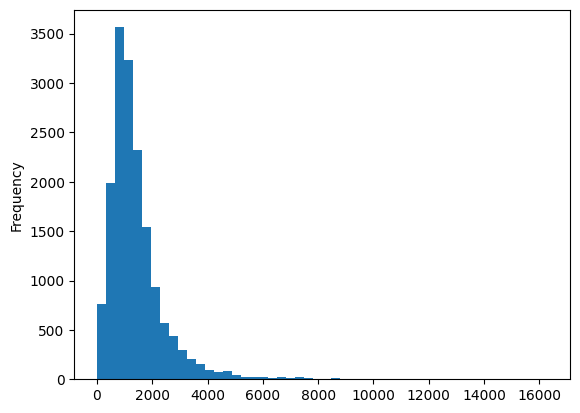

In [102]:
housing["population"].plot(kind="hist",bins=50)
plt.show()

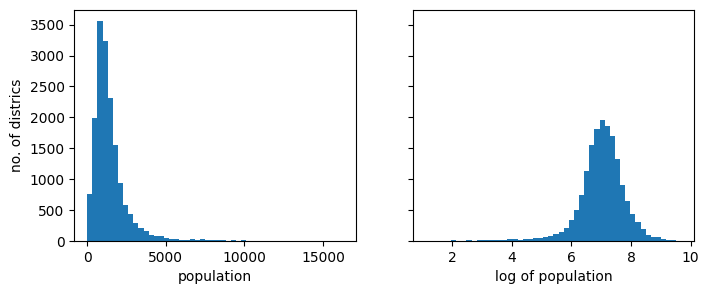

In [103]:
fig,axis = plt.subplots(1,2,figsize=(8, 3), sharey=True)
housing["population"].plot(kind="hist",bins=50,ax=axis[0])
housing["population"].apply(np.log).plot(kind="hist",bins=50,ax=axis[1])
axis[0].set_xlabel("population")
axis[1].set_xlabel("log of population")
axis[0].set_ylabel("no. of districs")
plt.show()

we should apply transformation befor scaling. if feature's distribution has a heavy tail, then a lot of values are squash (maximum values are very very colsed and small range). we can apply square root, if too much tailed apply log transformation.
in above figure after applying transformation, it almost look like normal distribuion.

Another approach to handle heavy-tailed features consists in bucketizing the
feature.

np.percentile(housing["population"],1) This finds the value that separates a certain percentage of the data. for expample
 1.  np.percentile(housing["population"],0) is min value of population
 2.  np.percentile(housing["population"],100) is max value of population
 3.  np.percentile(housing["population"],10) is 511.10000000000014.
 4.  if the 10th percentile is $2.0, it means 10% of districts have an income below 2.0.

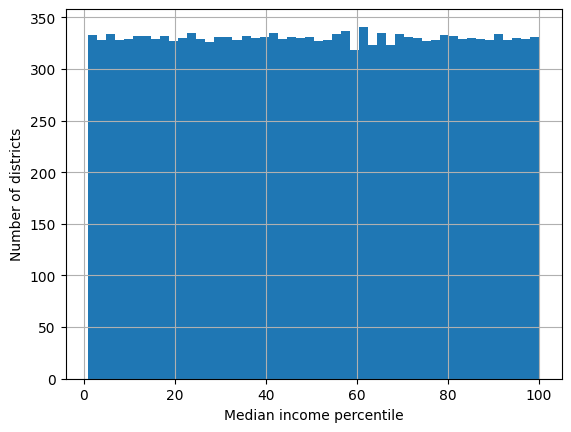

In [104]:
percentile = [np.percentile(housing["population"],i) for i in range(1,100)] # this create 99 numbers 
bukkets = pd.cut(housing["population"],bins=[-np.inf]+percentile+[np.inf],labels=range(1,101)) # bins is walls for bukkets
bukkets.hist(bins=50)
plt.xlabel("Median income percentile")
plt.ylabel("Number of districts")
plt.show()
# Note: incomes below the 1st percentile are labeled 1, and incomes above the
# 99th percentile are labeled 100. This is why the distribution below ranges
# from 1 to 100 (not 0 to 100).

above way is for Bucketizing Heavy-Tailed Features . also we have a Handling Multimodal Distributions (Multiple Peaks)

we can also do for labels. if it is highly tailed, we apply log transformation. but if we use linear regression model, it predicts log values not normal values. we will need to compute exponential. luckily, scikit-lear's transformers have a inverse_transform() method. \
For example, the following code example shows how to scale the labels using a
StandardScale,then train a simple linear
regression model on the resulting scaled labels and use it to make predictions
on some new data, which we transform back to the original scale using the
trained scaler’s inverse_transform() method. for simplicity we only take one feature.

In [105]:
from sklearn.linear_model import LinearRegression

In [106]:
targrt_scalar = StandardScaler()
housing_labels_scaled = targrt_scalar.fit_transform(housing_labels.to_frame()) # StandardScaler expects 2D inputs.
model = LinearRegression()
model.fit(housing[["median_income"]],housing_labels_scaled)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [107]:
new_data = housing[["median_income"]].iloc[:5]  # imagine new data it is
scaled_pred = model.predict(new_data)

In [108]:
scaled_pred

array([[-0.64466228],
       [ 0.80674175],
       [-0.52302364],
       [-0.5853166 ],
       [-0.12415952]])

In [109]:
prediction = targrt_scalar.inverse_transform(scaled_pred)
prediction # orinal format data

array([[131997.15275877],
       [299359.35844434],
       [146023.37185694],
       [138840.33653057],
       [192016.61557639]])

 There is a simple metod which is given below, we no need to again convert. 

In [110]:
from sklearn.compose import TransformedTargetRegressor
model = TransformedTargetRegressor(LinearRegression(),transformer=StandardScaler())
model.fit(housing[["median_income"]],housing_labels_scaled)
predictions = model.predict(new_data)
predictions

array([[-0.64466228],
       [ 0.80674175],
       [-0.52302364],
       [-0.5853166 ],
       [-0.12415952]])

### Custom Transformers

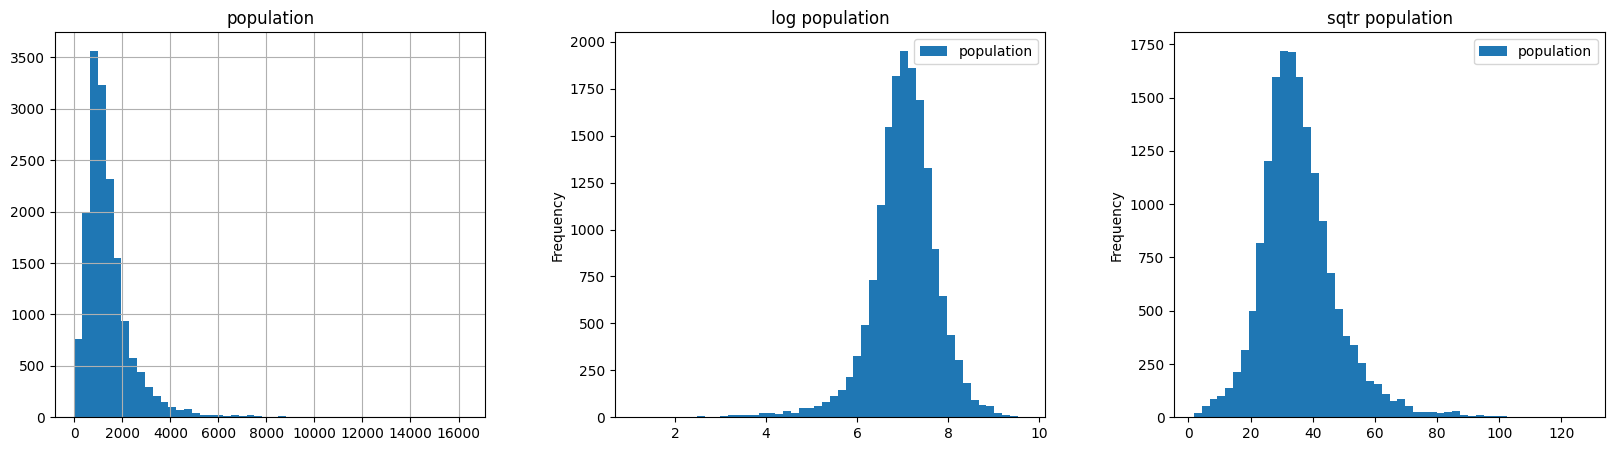

In [111]:
fig, axis = plt.subplots(1,3,figsize=(20,5))
housing[["population"]].hist(bins=50,ax=axis[0])
axis[0].set_title("population")
np.log(housing[["population"]]).plot(kind="hist",bins=50,ax=axis[1])
axis[1].set_title("log population")
np.sqrt(housing[["population"]]).plot(kind="hist",bins=50,ax = axis[2])
axis[2].set_title("sqtr population")
plt.show()

In [112]:
# using sklern

In [113]:
from sklearn.preprocessing import FunctionTransformer

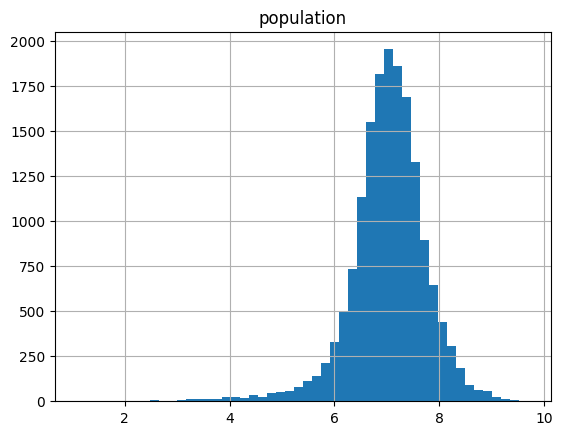

In [114]:
log_trans = FunctionTransformer(func=np.log,
    inverse_func=np.exp) # inverse_func is optional
population_log = log_trans.transform(housing[["population"]])
population_log.hist(bins=50)
plt.show()

In [115]:
# rbf kerner understanding

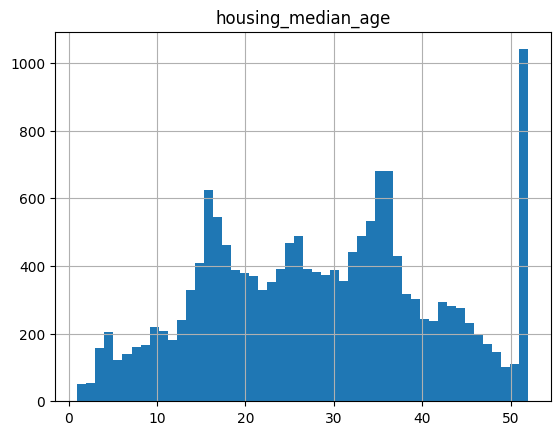

In [116]:
housing[["housing_median_age"]].hist(bins=50)
plt.show()

In [117]:
from sklearn.metrics.pairwise import rbf_kernel

In [118]:
rbf_trans = rbf_kernel(X=housing[["housing_median_age"]],Y=[[35]],gamma=0.1)
# it meansure how similar each point in housing_median_age wit 35. max(rbf_trans) = 1, min(rbf_trans) = 0.

In [119]:
np.round(rbf_trans,2)

array([[0.  ],
       [0.08],
       [0.67],
       ...,
       [0.  ],
       [0.67],
       [0.  ]], shape=(16512, 1))

In [120]:
rbf_transformer = FunctionTransformer(rbf_kernel,kw_args=dict(Y=[[35]],gamma=0.1))
age_simila_35 = rbf_transformer.transform(housing[["housing_median_age"]])
np.round(age_simila_35,2)

array([[0.  ],
       [0.08],
       [0.67],
       ...,
       [0.  ],
       [0.67],
       [0.  ]], shape=(16512, 1))

Note that there’s no inverse function for the RBF kernel, since there are
always two values at a given distance from a fixed point (except at distance
0). Also note that rbf_kernel() does not treat the features separately. If you
pass it an array with two features, it will measure the 2D distance (Euclidean)
to measure similarity. For example, here’s how to add a feature that will
measure the geographic similarity between each district and San Francisco:

In [121]:
# Measuring 2D Similarity
sans_coord = 37.7749, -122.41 # latitude, longitude
sans_transform = FunctionTransformer(rbf_kernel,kw_args=dict(Y=[sans_coord],gamma=0.1))
sans_similar = sans_transform.transform(housing[["latitude","longitude"]])
sans_similar

array([[0.999927  ],
       [0.05258419],
       [0.94864161],
       ...,
       [0.00388525],
       [0.05038518],
       [0.99868067]], shape=(16512, 1))

If a district is inside San Francisco, sans_similar will be 1.0.
If a district is in Los Angeles, sans_similar might be 0.001.

In [122]:
fun = lambda x: x*2
print(fun([1,2,3]))
ratio = lambda x: x[0]/x[1]
print(ratio(np.array([[1,2],[2,4]])))
ratio = lambda x: x[:,[0]]/x[:,[1]] # if we only give 0 instead [0], it reurn only 1D array. [0] gives 2D array 
print(ratio(np.array([[1,2],[2,4]])))

[1, 2, 3, 1, 2, 3]
[0.5 0.5]
[[0.5]
 [0.5]]


Custom transformers are also useful to combine features

In [123]:
# ratio transformation
ratio_trans = FunctionTransformer(lambda x : x[:,[0]]/x[:,[1]])
ratio_trans.transform(np.array([[1., 2.], [3., 4.]]))

array([[0.5 ],
       [0.75]])

 custom transformation class implementation:-

 BaseEstimator: Adding this as a base class gives you get_params() and set_params(), which allow you to tune your transformer automatically later.

TransformerMixin: This automatically adds the fit_transform() method by just running fit() followed by transform().

check_array & check_is_fitted: These are "safety check" tools from Scikit-Learn. They ensure the data you pass in is valid and that you aren't trying to transform data before the model has learned anything.

In [124]:
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.utils.validation import check_array, check_is_fitted

In [125]:
class StandardScalarClone(BaseEstimator, TransformerMixin):
    def __init__(self,with_mean = True): # no *args and **kargs 
        self.with_mean = with_mean
    def fit(self,X,Y=None): # Y is required eventhough we can't use it
        X = check_array(X)
        self.mean_ = X.mean(axis=0)
        self.scale_ = X.std(axis=0)
        self.n_features_in_ = X.shape[1]
        return self # always return self
    def transform(self,X):
        check_is_fitted(self)
        X = check_array(X)
        assert self.n_features_in_ == X.shape[1]#features are same in given x in fit and transformation.other wise raise arrert error
        if self.with_mean:
            X = X-self.mean_
        return X/ self.scale_
        

In [126]:
sc_popu = StandardScaler() # using sklearn standard 
sc_popu.fit(housing[["population"]])
sc_popu.transform(housing[["population"]])[:5]

array([[ 0.13746004],
       [-0.69377062],
       [-0.78876841],
       [ 0.38317548],
       [ 0.44437597]])

In [127]:
sc_clone_popu = StandardScalarClone()
sc_clone_popu.fit(housing[["population"]])
sc_clone_popu.transform(housing[["population"]])[:5]

array([[ 0.13746004],
       [-0.69377062],
       [-0.78876841],
       [ 0.38317548],
       [ 0.44437597]])

I skip the topic custom
transformer that uses a KMeans clusterer in the fit() method to identify the
main clusters in the training data, and then uses rbf_kernel() in thetransform() method to measure how similar each sample is to each cluster

In [128]:
from sklearn.cluster import KMeans

In [129]:
class ClusterSimilarity(BaseEstimator,TransformerMixin):
    def __init__(self,n_clusters=10, gamma=1.0, random_state=None):
        self.n_clusters = n_clusters
        self.gamma = gamma
        self.random_state = random_state
    def fit(self,X,y=None,sample_weight=None):
        self.kmeans_ = KMeans(self.n_clusters, random_state=self.random_state)
        self.kmeans_.fit(X, sample_weight=sample_weight)
        return self
    def transform(self, X):
        # self.kmeans_.cluster_centers_ is 10 x 2 matrix. [lati, longitudes] of 10 clusters
        return rbf_kernel(X, self.kmeans_.cluster_centers_, gamma=self.gamma) # X is 100 x 2 . so, result is 100 x 10, means each 100 districs how much related to 10 districs
    def get_feature_names_out(self, names=None):
        return [f"Cluster {i} similarity" for i in range(self.n_clusters)] # When you put this in a Scikit-Learn Pipeline, the pipeline needs to know what to call the new columns. 
                                                                            #This tells it to name them: "Cluster 0 similarity", "Cluster 1 similarity", etc.
    

In [130]:
x_geometry = housing[["latitude","longitude"]]
cluster_sim = ClusterSimilarity(10,1.0,42)
cluster_sim.fit(x_geometry)
housing_geometry_similarities = cluster_sim.transform(x_geometry)
housing_geometry_similarities[:2]

array([[4.58182914e-01, 1.24184704e-14, 8.14115996e-02, 3.43494968e-24,
        3.32927844e-07, 2.09502788e-04, 8.48921576e-04, 9.77032220e-01,
        2.38219102e-08, 3.81912645e-18],
       [6.51149524e-10, 9.57959641e-01, 8.64950185e-14, 2.71299003e-02,
        3.99203849e-02, 2.07891356e-04, 5.61404860e-27, 1.26096386e-13,
        1.10349080e-01, 3.54761008e-01]])

In [131]:
np.round(housing_geometry_similarities[:2],2)

array([[0.46, 0.  , 0.08, 0.  , 0.  , 0.  , 0.  , 0.98, 0.  , 0.  ],
       [0.  , 0.96, 0.  , 0.03, 0.04, 0.  , 0.  , 0.  , 0.11, 0.35]])

In [132]:
# below code directly copied

In [133]:
# # extra code – this cell generates Figure 2–19
# housing_renamed = housing.rename(columns={
# "latitude": "Latitude", "longitude": "Longitude",
# "population": "Population",
# "median_house_value": "Median house value (ᴜsᴅ)"})
# housing_renamed["Max cluster similarity"] = housing_geometry_similarities.max(axis=1)
# housing_renamed.plot(kind="scatter", x="Longitude", y="Latitude", grid=True,
# s=housing_renamed["Population"] / 100, label="Population",
# c="Max cluster similarity",
# cmap="jet", colorbar=True,
# legend=True, sharex=False, figsize=(10, 7))
# plt.plot(cluster_sim.kmeans_.cluster_centers_[:, 1],
#     cluster_sim.kmeans_.cluster_centers_[:, 0],linestyle="", color="black", marker="X", markersize=20,
#     label="Cluster centers")
# plt.legend(loc="upper right")
# plt.show()

### Transformation Pipelines

In [134]:
from sklearn.pipeline import Pipeline

In [135]:
num_pipeline = Pipeline([
    ("numeric_imputer",SimpleImputer(strategy="median")),
    ("numeric_standization",StandardScaler()),
])

In [136]:
# also use "passthrough" or "drop". if we skip anything.

In [137]:
from sklearn import set_config

In [138]:
set_config(display="diagram")

In [139]:
num_pipeline

,steps,"[('numeric_imputer', ...), ('numeric_standization', ...)]"
,transform_input,None
,memory,None
,verbose,False
,missing_values,nan
,strategy,'median'
,fill_value,None
,copy,True
,add_indicator,False
,keep_empty_features,False
,copy,True


If we don’t want to name the transformers, you can use the make_pipeline()
function instead; it takes transformers as positional arguments and creates a
Pipeline using the names of the transformers’ classes, in lowercase and
without underscores (e.g., "simpleimputer"):

In [140]:
from sklearn.pipeline import make_pipeline

In [141]:
num_pipeline = make_pipeline(SimpleImputer(strategy="median"),StandardScaler())

In [142]:
num_pipeline

,steps,"[('simpleimputer', ...), ('standardscaler', ...)]"
,transform_input,None
,memory,None
,verbose,False
,missing_values,nan
,strategy,'median'
,fill_value,None
,copy,True
,add_indicator,False
,keep_empty_features,False
,copy,True


In [143]:
num_pipeline.named_steps

{'simpleimputer': SimpleImputer(strategy='median'),
 'standardscaler': StandardScaler()}

In [144]:
# num_pipeline = make_pipeline(SimpleImputer(strategy="median"),StandardScaler(),StandardScaler())
# num_pipeline.named_steps

In [145]:
housing_num_prepared = num_pipeline.fit_transform(housing_nume)
# np.round(housing_num_prepared[:2],2)
housing_num_prepared[:2].round(2)

array([[-1.42,  1.01,  1.86,  0.31,  1.37,  0.14,  1.39, -0.94],
       [ 0.6 , -0.7 ,  0.91, -0.31, -0.44, -0.69, -0.37,  1.17]])

In [146]:
df_housing_num_prepared = pd.DataFrame(housing_num_prepared,
                                       index=housing_nume.index,
                                      columns=num_pipeline.get_feature_names_out())
df_housing_num_prepared[:2]

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income
13096,-1.423037,1.013606,1.861119,0.311912,1.368167,0.137460,1.394812,-0.936491
14973,0.596394,-0.702103,0.907630,-0.308620,-0.435925,-0.693771,-0.373485,1.171942


In [147]:
# # we can access individual transformers using index
# std = num_pipeline[1]
# std.fit_transform(housing_nume)

In [148]:
# # also access using names of steps
# num_pipeline['simpleimputer']

In [149]:
# so far we discussed numerical and categorical columns individual. using ColumnTransformer we can do both.

In [150]:
housing.columns

Index(['longitude', 'latitude', 'housing_median_age', 'total_rooms',
       'total_bedrooms', 'population', 'households', 'median_income',
       'ocean_proximity'],
      dtype='object')

In [151]:
num_columns = ['longitude', 'latitude', 'housing_median_age', 'total_rooms',
       'total_bedrooms', 'population', 'households', 'median_income']
cat_columns = ['ocean_proximity']

In [152]:
# now we have to prepare for categorical 
cat_pipeline = make_pipeline(SimpleImputer(strategy="most_frequent"),
                             OneHotEncoder(handle_unknown='ignore')) # handle_unknown is useful in transform() if it gets another columns it set to all to 0

In [153]:
num_pipeline = make_pipeline(SimpleImputer(strategy="median"),StandardScaler())

In [154]:
# cat_res = cat_pipeline.fit_transform(housing_cat)
# cat_res.toarray()

In [155]:
from sklearn.compose import ColumnTransformer

In [156]:
preprocessing = ColumnTransformer([
    ("num", num_pipeline, num_columns), # tuples of 3: (name, transformer, list of names of columns)
    ("cat", cat_pipeline, cat_columns),
])

scikit learn have a make_column_selector to give numeric and categorical columns.

In [157]:
from sklearn.compose import make_column_selector

In [158]:
preprocessing = ColumnTransformer([
    ("num", num_pipeline, make_column_selector(dtype_include=np.number)),
    ("cat", cat_pipeline, make_column_selector(dtype_include=object)),
])

If we want to not specify names sklearn do for us using make_column_transformer, it assign names for us.

In [159]:
from sklearn.compose import make_column_transformer

In [160]:
preprocessing = make_column_transformer(
    (num_pipeline, make_column_selector(dtype_include=np.number)),
    (cat_pipeline, make_column_selector(dtype_include=object)),
)
# above don't use [] inside function like we did in ColumnTransformer or pipeline

In [161]:
# now we ready to apply preprocessing pipeline to total data
housing_prepared = preprocessing.fit_transform(housing)

In [162]:
housing_prepared_df = pd.DataFrame(housing_prepared,columns=preprocessing.get_feature_names_out(),
                                  index = housing.index)


In [163]:
housing_prepared_df.head()

,pipeline-1__longitude,pipeline-1__latitude,pipeline-1__housing_median_age,pipeline-1__total_rooms,pipeline-1__total_bedrooms,pipeline-1__population,pipeline-1__households,pipeline-1__median_income,pipeline-2__ocean_proximity_<1H OCEAN,pipeline-2__ocean_proximity_INLAND,pipeline-2__ocean_proximity_ISLAND,pipeline-2__ocean_proximity_NEAR BAY,pipeline-2__ocean_proximity_NEAR OCEAN
13096,-1.423037,1.013606,1.861119,0.311912,1.368167,0.137460,1.394812,-0.936491,0.0,0.0,0.0,1.0,0.0
14973,0.596394,-0.702103,0.907630,-0.308620,-0.435925,-0.693771,-0.373485,1.171942,1.0,0.0,0.0,0.0,0.0
3785,-1.203098,1.276119,0.351428,-0.712240,-0.760709,-0.788768,-0.775727,-0.759789,0.0,1.0,0.0,0.0,0.0
14689,1.231216,-0.884924,-0.919891,0.702262,0.742306,0.383175,0.731375,-0.850281,0.0,1.0,0.0,0.0,0.0
20507,0.711362,-0.875549,0.589800,0.790125,1.595753,0.444376,1.755263,-0.180365,0.0,0.0,0.0,0.0,1.0


In [164]:
housing_prepared_df.shape

(16512, 13)

summary for upto above: 
1. Missing values in numerical features will be imputed by replacing them
with the median, as most ML algorithms don’t expect missing values. In
categorical features, missing values will be replaced by the most
frequent category. 
2. The categorical feature will be one-hot encoded, as most ML algorithms
only accept numerical inputs. 
3. A few ratio features will be computed and added: bedrooms_ratio,
rooms_per_house, and people_per_house. Hopefully these will better
correlate with the median house value, and thereby help the ML models. 
4. A few cluster similarity features will also be added. These will likely be
more useful to the model than latitude and longitude. 
5. Features with a long tail will be replaced by their logarithm, as most
models prefer features with roughly uniform or Gaussian distributions. 
6. All numerical features will be standardized, as most ML algorithms
prefer when all features have roughly the same scale.

In [165]:
# Now we impement above stps

In [166]:
# Before building the pipeline, you define how to calculate new information and how to name it.
# THis is for step 3
def column_ratio(X):
    return X[:,[0]]/X[:,[1]]
def ratio_name(function_transformer, feature_names_in):
    return ["ratio"]  # feature names out
# we can also define varible insteaed of function, but now we define function to return a pipeline 
def ratio_pipeline():
    return make_pipeline(
        SimpleImputer(strategy="median"),
        FunctionTransformer(func=column_ratio,feature_names_out=ratio_name),# to apply ratio on columns
        StandardScaler()
    )

--- 1

In [167]:
log_pipeline = make_pipeline(
    SimpleImputer(strategy="median"),
    FunctionTransformer(np.log,feature_names_out="one-to-one"),
    StandardScaler()
)

What does feature_names_out="one-to-one" mean?
Earlier, we used a custom function ratio_name because we were turning two columns into one ratio.

    Here, np.log is applied to each column individually.
    "one-to-one" is a shortcut in Scikit-Learn that tells the computer: "Don't change the column names. If I pass in 'population', the output name should still be 'population'."

In [168]:
cluster_sim = ClusterSimilarity(n_clusters=10, gamma=1.0, random_state=42)
# we don,t pass piple line, we directly pass cluster_sim. because we pipeline used when we want to do mutliple operation, we no need for
# this. if we want we also do like below
# cluster_pipeline = make_pipeline(
#     SimpleImputer(strategy="median"),
#     cluster_sim
# )

In [169]:
default_num_pipeline = make_pipeline(
    SimpleImputer(strategy="median"),
    StandardScaler()
)

In [170]:
# combine all pipelineas
preprocessing = ColumnTransformer([
    ("bedrooms_ratio",ratio_pipeline(),["total_bedrooms","total_rooms"]),
    ("rooms_per_house",ratio_pipeline(),["total_rooms","households"]),
    ("people_per_house",ratio_pipeline(),["population","households"]),
    ("log",log_pipeline,["total_bedrooms", "total_rooms", "population",
                        "households", "median_income"]),
    ("geo",cluster_sim,["latitude","longitude"]),
    ("cat",cat_pipeline,make_column_selector(dtype_include=object)),
],remainder=default_num_pipeline, # this is for housing_median_age
                                 )

By setting remainder=default_num_pipeline, you are saying: "If I forgot a column, don't drop it. Just run it through the basic imputer and scaler.\
we don't add default_num_pipeline for numeric. because we already do in ratio_pipeline,log_pipeline which contains SimpleImputer,StandardScaler. 

In [171]:
preprocessing

,transformers,"[('bedrooms_ratio', ...), ('rooms_per_house', ...), ...]"
,remainder,Pipeline(step...ardScaler())])
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True
,force_int_remainder_cols,'deprecated'
,missing_values,nan
,strategy,'median'
,fill_value,None


In [172]:
housing_prepared = preprocessing.fit_transform(housing)

In [173]:
housing_prepared.shape

(16512, 24)

In [174]:
preprocessing.get_feature_names_out()

array(['bedrooms_ratio__ratio', 'rooms_per_house__ratio',
       'people_per_house__ratio', 'log__total_bedrooms',
       'log__total_rooms', 'log__population', 'log__households',
       'log__median_income', 'geo__Cluster 0 similarity',
       'geo__Cluster 1 similarity', 'geo__Cluster 2 similarity',
       'geo__Cluster 3 similarity', 'geo__Cluster 4 similarity',
       'geo__Cluster 5 similarity', 'geo__Cluster 6 similarity',
       'geo__Cluster 7 similarity', 'geo__Cluster 8 similarity',
       'geo__Cluster 9 similarity', 'cat__ocean_proximity_<1H OCEAN',
       'cat__ocean_proximity_INLAND', 'cat__ocean_proximity_ISLAND',
       'cat__ocean_proximity_NEAR BAY', 'cat__ocean_proximity_NEAR OCEAN',
       'remainder__housing_median_age'], dtype=object)

In [175]:
df_housing_prepared = pd.DataFrame(housing_prepared,columns=preprocessing.get_feature_names_out(),index=housing.index)
df_housing_prepared.head()

,bedrooms_ratio__ratio,rooms_per_house__ratio,people_per_house__ratio,log__total_bedrooms,log__total_rooms,log__population,log__households,log__median_income,geo__Cluster 0 similarity,geo__Cluster 1 similarity,geo__Cluster 2 similarity,geo__Cluster 3 similarity,geo__Cluster 4 similarity,geo__Cluster 5 similarity,geo__Cluster 6 similarity,geo__Cluster 7 similarity,geo__Cluster 8 similarity,geo__Cluster 9 similarity,cat__ocean_proximity_<1H OCEAN,cat__ocean_proximity_INLAND,cat__ocean_proximity_ISLAND,cat__ocean_proximity_NEAR BAY,cat__ocean_proximity_NEAR OCEAN,remainder__housing_median_age
13096,1.846624,-0.866027,-0.330204,1.324114,0.637892,0.456906,1.310369,-1.071522,4.581829e-01,1.241847e-14,8.141160e-02,3.434950e-24,3.329278e-07,2.095028e-04,8.489216e-04,9.770322e-01,2.382191e-08,3.819126e-18,0.0,0.0,0.0,1.0,0.0,1.861119
14973,-0.508121,0.024550,-0.253616,-0.252671,-0.063576,-0.711654,-0.142030,1.194712,6.511495e-10,9.579596e-01,8.649502e-14,2.712990e-02,3.992038e-02,2.078914e-04,5.614049e-27,1.260964e-13,1.103491e-01,3.547610e-01,1.0,0.0,0.0,0.0,0.0,0.907630
3785,-0.202155,-0.041193,-0.051041,-0.925266,-0.859927,-0.941997,-0.913030,-0.756981,3.432506e-01,4.261141e-15,4.483096e-01,1.041079e-24,5.084725e-08,4.108863e-04,5.641131e-03,7.303265e-01,2.508224e-08,2.669659e-18,0.0,1.0,0.0,0.0,0.0,0.351428
14689,-0.149006,-0.034858,-0.141475,0.952773,0.943475,0.670700,0.925373,-0.912253,2.244844e-15,2.704823e-01,2.813014e-19,4.649510e-01,5.823840e-05,1.595594e-07,5.913326e-35,5.201263e-20,1.712982e-03,8.874598e-01,0.0,1.0,0.0,0.0,0.0,-0.919891
20507,0.963208,-0.666554,-0.306148,1.437622,1.003590,0.719093,1.481464,0.034537,1.090228e-11,9.422206e-01,6.016730e-16,1.092616e-01,9.773465e-03,1.371210e-05,5.421817e-30,1.048030e-15,2.568824e-02,5.279506e-01,0.0,0.0,0.0,0.0,1.0,0.589800


# Select and Train a Model

### Train and Evaluate on the Training Set

In [176]:
from sklearn.linear_model import LinearRegression

In [177]:
lin_reg = make_pipeline(preprocessing,LinearRegression())

--- 2

In [178]:
lin_reg.fit(housing,housing_labels)

,steps,"[('columntransformer', ...), ('linearregression', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('bedrooms_ratio', ...), ('rooms_per_house', ...), ...]"
,remainder,Pipeline(step...ardScaler())])
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [179]:
housing_predictions = lin_reg.predict(housing)

In [180]:
housing_predictions[:2]

array([245970.16089315, 372738.06971503])

In [181]:
housing_predictions[:5].round(-2) # -2 = rounded to the nearest hundred

array([246000., 372700., 135700.,  91400., 330900.])

In [182]:
housing_labels.iloc[:5].values

array([458300., 483800., 101700.,  96100., 361800.])

In [183]:
from sklearn.metrics import root_mean_squared_error

we choose RMSE as a performence matrix.
the reason we take RMSE is
1. MSE give squared unit. but, RMSE gives same unit.
2. MAE (Mean Absolute Error) treats all errors linearly. It’s like a "lenient" teacher.RMSE is the "strict" teacher. Because of that initial squaring, the RMSE will always be higher than the MAE if there are large outliers.

In [184]:
lin_rmse = root_mean_squared_error(housing_labels,housing_predictions)
lin_rmse

68972.88910758533

It is not a good score\
--- 3

In [185]:
from sklearn.tree import DecisionTreeRegressor

In [186]:
tree_reg = make_pipeline(preprocessing,DecisionTreeRegressor(random_state=42))
tree_reg.fit(housing,housing_labels)

,steps,"[('columntransformer', ...), ('decisiontreeregressor', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('bedrooms_ratio', ...), ('rooms_per_house', ...), ...]"
,remainder,Pipeline(step...ardScaler())])
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [187]:
housing_predictions = tree_reg.predict(housing)

In [188]:
housing_predictions[:5],housing_labels[:5]

(array([458300., 483800., 101700.,  96100., 361800.]),
 13096    458300.0
 14973    483800.0
 3785     101700.0
 14689     96100.0
 20507    361800.0
 Name: median_house_value, dtype: float64)

In [189]:
tree_rmse = root_mean_squared_error(housing_labels,housing_predictions)
tree_rmse

0.0

It lokks like overfitting.

### Better Evaluation Using Cross-Validation

we can use train_test_split() to split training set into a smaller training set and a validation set.\
now we are using k_-fold cross-validation for 10 times and 10 splits.

In [190]:
from sklearn.model_selection import cross_val_score

In [191]:
tree_rmse = -cross_val_score(tree_reg,housing,housing_labels,scoring="neg_root_mean_squared_error",cv=10)

Scikit-Learn’s cross-validation features expect a utility function (greater is better) rather
than a cost function (lower is better), so the scoring function is actually the opposite of the
RMSE. It’s a negative value, so you need to switch the sign of the output to get the RMSE
scores.

In [192]:
pd.Series(tree_rmse).describe()

count       10.000000
mean     66573.734600
std       1103.402323
min      64607.896046
25%      66204.731788
50%      66388.272499
75%      66826.257468
max      68532.210664
dtype: float64

In [193]:
from sklearn.ensemble import RandomForestRegressor

In [194]:
forest_reg = make_pipeline(preprocessing,RandomForestRegressor(random_state=42))

In [195]:
# forest_rmse = -cross_val_score(forest_reg,housing,housing_labels,scoring="neg_root_mean_squared_error",cv=10)
# forest_rmse

In [196]:
# pd.Series(forest_rmse).describe()

count       10.000000
mean     47038.092799
std       1021.491757
min      45495.976649
25%      46510.418013
50%      47118.719249
75%      47480.519175
max      49140.832210
dtype: float64

In [197]:
# forest_reg.fit(housing,housing_labels)
# housing_predictions = forest_reg.predict(housing)
# forest_rmse = root_mean_squared_error(housing_labels,housing_predictions)
# forest_rmse

17551.2122500877

if we observe above cell , rmse value is 17551.2122500877 , but in crossvalidation rmse averave is  47038.092799. so, the model is overfitting.

The training error is much lower than the validation error, which usually means that the model has overfit the training set. Another possible explanation may be that there's a mismatch between the training data and the validation data, but it's not the case here, since both came from the same dataset that we shuffled and split in two parts.

## Fine-Tune Your Model

#### Grid Search

In [198]:
from sklearn.model_selection import GridSearchCV

In [199]:
full_pipeline = Pipeline([
    ("preprocessing",preprocessing),
    ("random_forest",RandomForestRegressor(random_state=42)),
])

In [200]:
param_grid = [
{'preprocessing__geo__n_clusters': [5, 8, 10],
'random_forest__max_features': [4, 6, 8]},
{'preprocessing__geo__n_clusters': [10, 15],
'random_forest__max_features': [6, 8, 10]},
]

There is a reason why we are taking "preprocessing__geo__n_clusters" like this. It divide by __ . first it check the preprocessing, after in preprocessing check geo, after n_clusters.  \
total : 3x3 = 9 ; 2x 3 =6 ; 9+ 6 = 15 combinations. and we set cv = 3 below. so, 15 x 3 = 45 combination

In [202]:
grid_search = GridSearchCV(full_pipeline,param_grid,scoring="neg_root_mean_squared_error",cv = 3)

In [ ]:
# this code takes a lot of time for my laptop
# grid_search.fit(housing,housing_labels)

In [203]:
# grid_search.best_params_

AttributeError: 'GridSearchCV' object has no attribute 'best_params_'

In [204]:
# grid_search.cv_results_

AttributeError: 'GridSearchCV' object has no attribute 'cv_results_'

In [205]:
# grid_search.best_estimator_

In [206]:
# cv_res = pd.DataFrame(grid_search.cv_results_)
# cv_res.sort_values(by="mean_test_score", ascending=False, inplace=True)
# # we no need to see total columns , only few is enough
# cv_res = cv_res[["param_preprocessing__geo__n_clusters",
#                  "param_random_forest__max_features", "split0_test_score",
#                  "split1_test_score", "split2_test_score", "mean_test_score"]]
# # we take cv = 3. so there is 3 splits for every combination. that's why we take split0_test_score, split1_...,split2_....
# # rename columns with simple words
# score_cols = ["split0", "split1", "split2", "mean_test_rmse"]
# cv_res.colmns = ["n_clusters","max_features"] + score_cols
# # we already dicussed, put - ve sign for RMSE for this crossvalidation
# cv_res[score_cols] = - cv_res[score_cols].round(-2).astype(np.int64)

# cv_res.head()

### Randomized Search

It select random combinations.it evaluates a fixed number of combinations, we have parameter n_iter=10. For each hyperparameter, you must provide either a list of possible values like [1,2,3], or a probability distribution.

In [209]:
# from sklearn.model_selection import RandomizedSearchCV
# from scipy.stats import randint

In [212]:
# param_distribs = {"preprocessing__geo__n_clusters":randint(low= 3,high = 50),
#                  "random_forest__max_features":randint(low= 2, high = 20)}

--- 4

In [213]:
# rnd_search = RandomizedSearchCV(full_pipeline,param_distribs,n_iter=10,cv = 3,
#                                 scoring="neg_root_mean_squared_error",random_state=42)

In [214]:
# below code take some time
# rnd_search.fit(housing,housing_labels)

In [215]:
# # same like we did above to see results
# cv_res = pd.DataFrame(rnd_search.cv_results_)
# cv_res.sort_values(by="mean_test_score", ascending=False, inplace=True)
# cv_res = cv_res[["param_preprocessing__geo__n_clusters",
#                  "param_random_forest__max_features", "split0_test_score",
#                  "split1_test_score", "split2_test_score", "mean_test_score"]]
# cv_res.columns = ["n_clusters", "max_features"] + score_cols
# cv_res[score_cols] = -cv_res[score_cols].round().astype(np.int64)
# cv_res.head()

Scikit-Learn also has HalvingRandomSearchCV and HalvingGridSearchCV
hyperparameter search classes. Their goal is to use the computational
resources more efficiently, either to train faster or to explore a larger
hyperparameter space.

### Analyzing the Best Models and Their Errors

In [218]:
# When we run a Random Search (RandomizedSearchCV), we are testing hundreds of different "versions" of your pipeline.
# best_estimator_ stores the one single pipeline that got the lowest error (lowest RMSE).

--- 5

In [219]:
# final_model = rnd_search.best_estimator_ # including preprocessing

In [220]:
# feature_importances = final_model["random_forest"].feature_importances_
# feature_importances.round(2)

In [228]:
sorted(list(zip([1,22,3],["hii","hello","viaau"]))) # sort based on [1,2,3]

[(1, 'hii'), (3, 'viaau'), (22, 'hello')]

In [229]:
# sorted(zip(feature_importances,final_model["random_forest"].feature_names_in_),reverse=True)

In [241]:
# most = sorted(zip(feature_importances,final_model["random_forest"].feature_names_in_),reverse=True)[:10]
# y = [most[i][1] for i in range(len(most))]
# width = [most[i][0] for i in range(len(most))]
# plt.barh(y,width)
# plt.show()

Now is also a good time to ensure that your model not only works well on
average, but also on all categories of districts, whether they’re rural or urban,
rich or poor, northern or southern, minority or not, etc. Creating subsets of
your validation set for each category takes a bit of work, but it’s important: if
your model performs poorly on a whole category of districts, then it should
probably not be deployed until the issue is solved, or at least it should not be
used to make predictions for that category, as it may do more harm than
good.

## Evaluate Your System on the Test Set

In [247]:
X_test = strat_test_set.drop("median_house_value",axis=1)
y_test = strat_test_set["median_house_value"].copy()

In [248]:
# final_predictions = final_model.predict(X_test)

In [249]:
# final_rmse = root_mean_squared_error(y_test,final_predictions)
# print(final_rmse)

--- 6

In [250]:
# from scipy import stats
# confidence = 0.95
# squared_errors = (final_predictions - y_test) ** 2
# mean = squared_errors.mean()
# m = len(squared_errors)
# interval = np.sqrt(stats.t.interval(confidence, m-1,loc=mean,scale=stats.sem(squared_errors)))
# print(f"Final RMSE: ${final_rmse:.2f}")
# print(f"95% Confidence Interval: {interval}")

### Launch

In [1]:
import joblib

In [3]:
# joblib.dump(final_model,"california_housing_model.pkl") # save the model

joblib does NOT save:
the source code of ClusterSimilarity,
the source code of column_ratio,
the source code of ratio_name.
Instead, it saves:
the trained parameters,
the structure of the pipeline,
the names and locations of the classes/functions used.
Think of it like this:
joblib saves “Use this class called ClusterSimilarity”,
not “Here is the code of ClusterSimilarity” \
Python tries to reconstruct the object.
Internally it says:
“I see an object of type ClusterSimilarity.
Where is ClusterSimilarity defined?”
If Python cannot find it, you get errors

In [5]:
# # load the model
# # 1. import all required sklearn classes
# from sklearn.cluster import KMeans
# from sklearn.base import BaseEstimator, TransformerMixin
# from sklearn.metrics.pairwise import rbf_kernel
# # 2. define custom functions
# def column_ratio(X):
#     ...
# def ratio_name(function_transformer, feature_names_in):
#     ...
# # 3. define custom classes
# class ClusterSimilarity(BaseEstimator, TransformerMixin):
#     ...
# # 4. now load the model
# final_model_reloaded = joblib.load("california_housing_model.pkl")
# # 5. use it
# new_data = housing.iloc[:5]
# predictions = final_model_reloaded.predict(new_data)